# Task 1

**Task 1**: Load, Inspect, and Scale the Data. In this step I load the Wine dataset straight from Scikit-Learn. It has 178 wines, each described by 13 chemical measurements, like alcohol, color intensity, and proline. It also has the real wine type, but I keep that on the side and don't use it for clustering. I print the size of the table, the basic stats for each column, and a count of missing values. Then I scale all 13 columns with StandardScaler, which shifts each column so its average is 0 and spreads it so the typical distance from the average is 1. To show the effect, I draw a box plot of all 13 columns before scaling and another after scaling, side by side.

# Task 1 Code

Dimensions: (178, 13)
Missing values: 0
                                    mean         std     min      max
alcohol                        13.000618    0.811827   11.03    14.83
malic_acid                      2.336348    1.117146    0.74     5.80
ash                             2.366517    0.274344    1.36     3.23
alcalinity_of_ash              19.494944    3.339564   10.60    30.00
magnesium                      99.741573   14.282484   70.00   162.00
total_phenols                   2.295112    0.625851    0.98     3.88
flavanoids                      2.029270    0.998859    0.34     5.08
nonflavanoid_phenols            0.361854    0.124453    0.13     0.66
proanthocyanins                 1.590899    0.572359    0.41     3.58
color_intensity                 5.058090    2.318286    1.28    13.00
hue                             0.957449    0.228572    0.48     1.71
od280/od315_of_diluted_wines    2.611685    0.709990    1.27     4.00
proline                       746.893258  314.9074

/tmp/ipykernel_1636/3169534774.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(X.values, labels=range(1, 14))
/tmp/ipykernel_1636/3169534774.py:22: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(X_scaled, labels=range(1, 14))


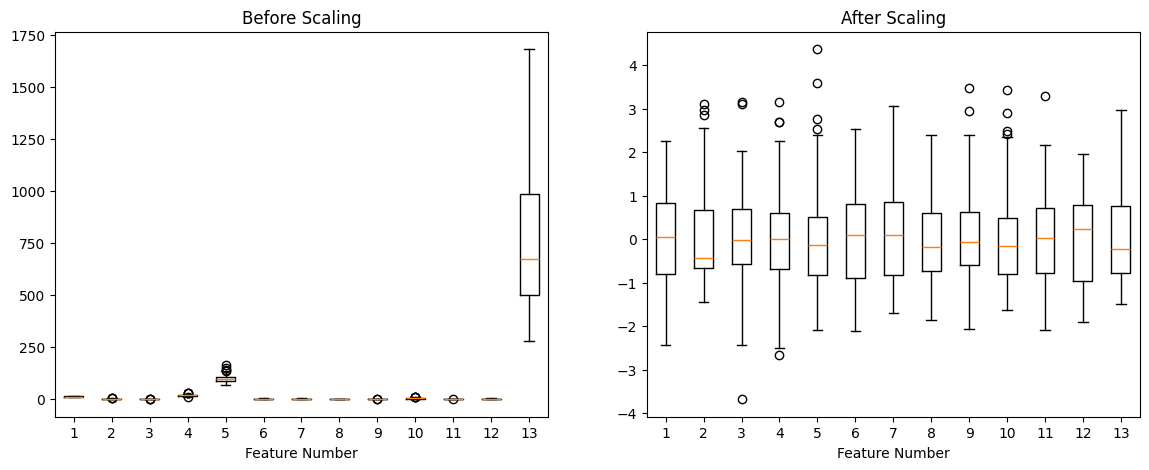

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)
y = wine.target

print("Dimensions:", X.shape)
print("Missing values:", X.isnull().sum().sum())
print(X.describe().T[["mean", "std", "min", "max"]])

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].boxplot(X.values, labels=range(1, 14))
axes[0].set_title("Before Scaling")
axes[0].set_xlabel("Feature Number")
axes[1].boxplot(X_scaled, labels=range(1, 14))
axes[1].set_title("After Scaling")
axes[1].set_xlabel("Feature Number")
plt.show()

# Task 2

**Task 2:** Elbow Method and Silhouette Scores. In this step I try K-Means with every number of groups from 1 to 10 on the scaled wines. For each number of groups, I record two scores. The first is the inertia, which is the total distance from each wine to the center of its group, so a smaller number means tighter groups. The second is the silhouette score, which measures how well each wine fits its own group compared to the next closest group. It goes from -1 to 1. It needs at least 2 groups, so I only compute it for 2 to 10. I plot both side by side and print the best number of groups that each one suggests. For the elbow, I find the point where the curve bends the most, and for the silhouette, I take the number of groups with the highest score.

# Task 2 Code

Optimal k from the elbow: 3
Optimal k from the silhouette: 3
k = 2, silhouette = 0.2593
k = 3, silhouette = 0.2849
k = 4, silhouette = 0.2602
k = 5, silhouette = 0.2016
k = 6, silhouette = 0.2372
k = 7, silhouette = 0.2036
k = 8, silhouette = 0.1570
k = 9, silhouette = 0.1499
k = 10, silhouette = 0.1436


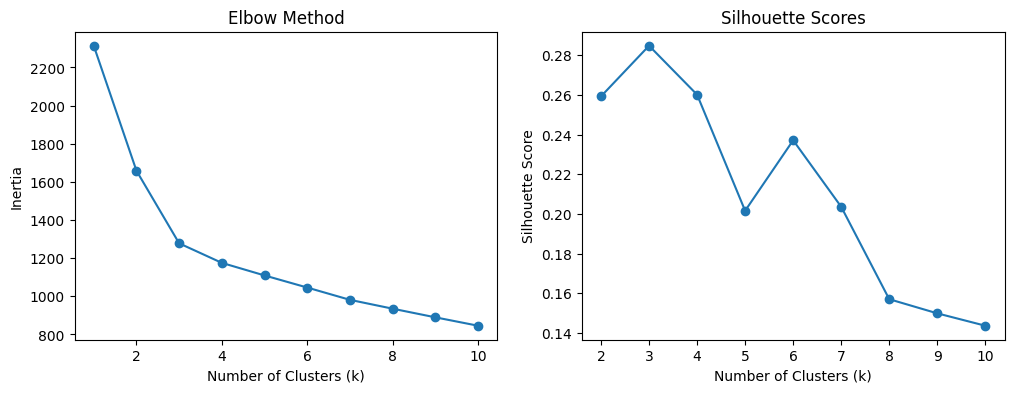

In [2]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

ks = range(1, 11)
inertias = []
sil_scores = []

for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    if k >= 2:
        sil_scores.append(silhouette_score(X_scaled, labels))

bend = np.diff(np.diff(inertias))
best_elbow = np.argmax(bend) + 2
best_sil = np.argmax(sil_scores) + 2

print("Optimal k from the elbow:", best_elbow)
print("Optimal k from the silhouette:", best_sil)
for k, s in zip(range(2, 11), sil_scores):
    print(f"k = {k}, silhouette = {s:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")
axes[1].plot(range(2, 11), sil_scores, marker="o")
axes[1].set_title("Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")
plt.show()

# Task 3

**Task 3:** PCA and Voronoi Decision Boundaries. In this step I squash the 13 scaled measurements down to just 2 values per wine using PCA, so I can draw the wines on a flat 2D chart. I use this only for drawing. Then I run K-Means with 3 groups on those 2 values. To show the decision boundaries, I color the whole chart by which group center is closest to each spot. I plot every wine on top, colored by its group, and mark the 3 group centers with big X marks. I also print how much of the total information the 2 PCA values keep.

# Task 3 Code

Variance kept by 2 components: 0.5541


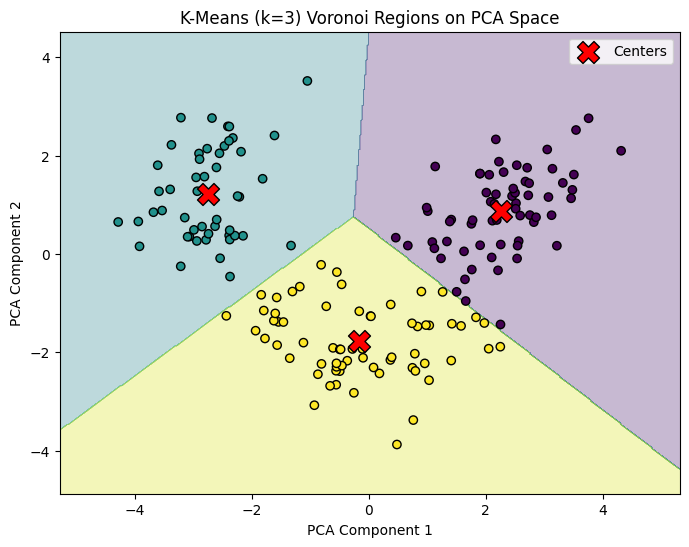

In [3]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)
print("Variance kept by 2 components:", round(pca.explained_variance_ratio_.sum(), 4))

km2 = KMeans(n_clusters=3, n_init=10, random_state=42)
km2.fit(X_pca)

xx, yy = np.meshgrid(
    np.linspace(X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1, 500),
    np.linspace(X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1, 500))
Z = km2.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx, yy, Z, alpha=0.3)
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=km2.labels_, edgecolor="k")
plt.scatter(km2.cluster_centers_[:, 0], km2.cluster_centers_[:, 1],
            marker="X", s=250, c="red", edgecolor="k", label="Centers")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("K-Means (k=3) Voronoi Regions on PCA Space")
plt.legend()
plt.show()

# Task 4

**Task 4:** Distance Profiles for Five Wines. In this step I go back to all 13 measurements and fit K-Means with 3 groups on the full scaled data. Then I pick 5 wines from different parts of the dataset. For each one, I calculate its distance to the center of every group. I draw the table as a heatmap, where a darker color means a bigger distance, and I print the number in each box. For each wine I put a red box around its smallest distance. A wine with one small distance and two big ones clearly belongs to one group, and a wine with two similar distances sits near the border between two groups.

# Task 4 Code

Distance matrix (rows = wines, columns = cluster centers):
[[5.19 6.   1.88]
 [3.98 5.55 1.83]
 [2.98 3.26 4.84]
 [4.9  6.77 5.6 ]
 [5.48 3.11 5.68]]
Assigned clusters: [2 2 0 0 1]


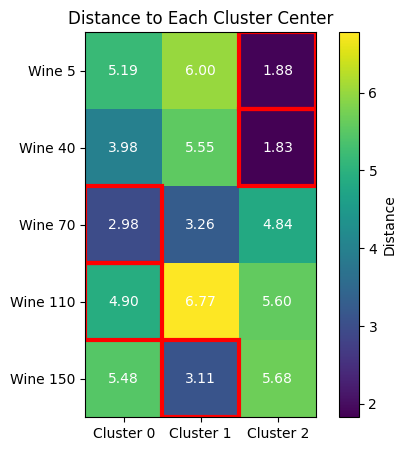

In [4]:
km13 = KMeans(n_clusters=3, n_init=10, random_state=42)
km13.fit(X_scaled)

picks = [5, 40, 70, 110, 150]
dist = km13.transform(X_scaled[picks])
assigned = km13.predict(X_scaled[picks])

print("Distance matrix (rows = wines, columns = cluster centers):")
print(np.round(dist, 2))
print("Assigned clusters:", assigned)

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(dist, cmap="viridis")
for i in range(5):
    for j in range(3):
        ax.text(j, i, f"{dist[i, j]:.2f}", ha="center", va="center", color="white")
    ax.add_patch(plt.Rectangle((np.argmin(dist[i]) - 0.5, i - 0.5), 1, 1,
                               fill=False, edgecolor="red", linewidth=3))
ax.set_xticks(range(3))
ax.set_xticklabels(["Cluster 0", "Cluster 1", "Cluster 2"])
ax.set_yticks(range(5))
ax.set_yticklabels([f"Wine {p}" for p in picks])
ax.set_title("Distance to Each Cluster Center")
plt.colorbar(im, label="Distance")
plt.show()

# Task 5

**Task 5:** DBSCAN. In this step I try a different kind of clustering called DBSCAN. I run DBSCAN on all 13 scaled measurements with a few different values of eps and min_samples, and print the number of groups and the number of noise wines for each combination, so I can see how sensitive it is to the settings. Then I choose one setting, print its results, and draw the wines on the 2D PCA chart, with the groups in different colors and the noise wines as black X marks.

# Task 5 Code

eps = 1.5, min_samples = 3: clusters = 8, noise = 147
eps = 1.5, min_samples = 5: clusters = 0, noise = 178
eps = 1.5, min_samples = 10: clusters = 0, noise = 178
eps = 2.0, min_samples = 3: clusters = 5, noise = 64
eps = 2.0, min_samples = 5: clusters = 5, noise = 85
eps = 2.0, min_samples = 10: clusters = 1, noise = 139
eps = 2.5, min_samples = 3: clusters = 1, noise = 23
eps = 2.5, min_samples = 5: clusters = 1, noise = 24
eps = 2.5, min_samples = 10: clusters = 2, noise = 32
eps = 3.0, min_samples = 3: clusters = 2, noise = 7
eps = 3.0, min_samples = 5: clusters = 1, noise = 11
eps = 3.0, min_samples = 10: clusters = 1, noise = 12

Chosen: eps = 3.0, min_samples = 3
Clusters found: 2
Noise points: 7


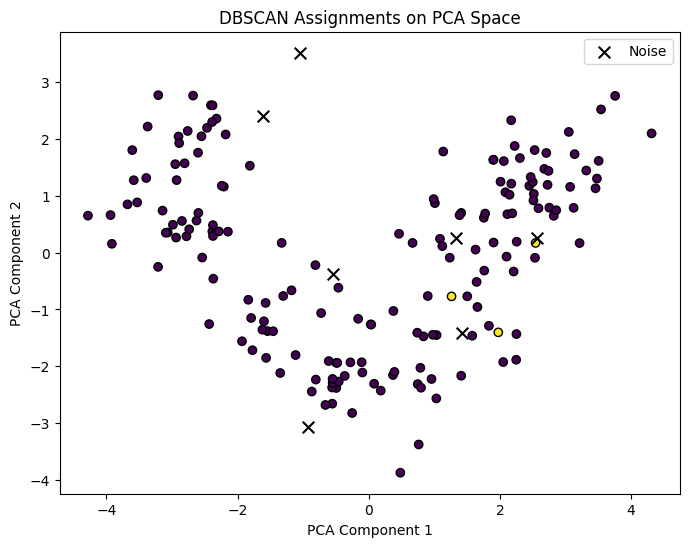

In [6]:
from sklearn.cluster import DBSCAN

for eps in [1.5, 2.0, 2.5, 3.0]:
    for ms in [3, 5, 10]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        print(f"eps = {eps}, min_samples = {ms}: clusters = {len(set(lab) - {-1})}, noise = {(lab == -1).sum()}")

eps_best, ms_best = 3.0, 3
db_labels = DBSCAN(eps=eps_best, min_samples=ms_best).fit_predict(X_scaled)
print()
print(f"Chosen: eps = {eps_best}, min_samples = {ms_best}")
print("Clusters found:", len(set(db_labels) - {-1}))
print("Noise points:", (db_labels == -1).sum())

plt.figure(figsize=(8, 6))
core = db_labels != -1
plt.scatter(X_pca[core, 0], X_pca[core, 1], c=db_labels[core], edgecolor="k")
plt.scatter(X_pca[~core, 0], X_pca[~core, 1], c="black", marker="x", s=70, label="Noise")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("DBSCAN Assignments on PCA Space")
plt.legend()
plt.show()

# Task 6

**Task 6:** HDBSCAN. In this step I try HDBSCAN. I run it on all 13 scaled measurements with min_cluster_size = 5 and min_samples = 5, so a group needs at least 5 wines to count. I print the number of groups and the number of noise wines, and I draw the wines on the 2D PCA chart with each group in its own color and the noise wines as black X marks.

# Task 6 Code

Clusters found: 2
Noise points: 58


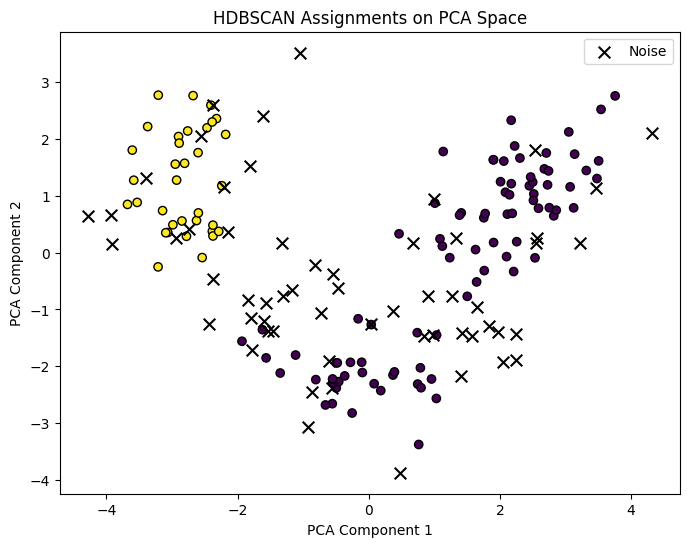

In [7]:
from sklearn.cluster import HDBSCAN

hdb = HDBSCAN(min_cluster_size=5, min_samples=5)
hdb_labels = hdb.fit_predict(X_scaled)

print("Clusters found:", len(set(hdb_labels) - {-1}))
print("Noise points:", (hdb_labels == -1).sum())

plt.figure(figsize=(8, 6))
core = hdb_labels != -1
plt.scatter(X_pca[core, 0], X_pca[core, 1], c=hdb_labels[core], edgecolor="k")
plt.scatter(X_pca[~core, 0], X_pca[~core, 1], c="black", marker="x", s=70, label="Noise")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("HDBSCAN Assignments on PCA Space")
plt.legend()
plt.show()

# Task 7

**Task 7:** Single-Linkage Dendrogram. In this step I build a family tree of the wines using single linkage hierarchical clustering on the 13 scaled measurements. The dendrogram draws this as a tree. The wines are along the bottom, and each time two groups join, a line connects them at a height equal to the distance between them. Short joins at the bottom mean the wines are very similar, and tall joins at the top mean very different groups are being merged.

# Task 7 Code

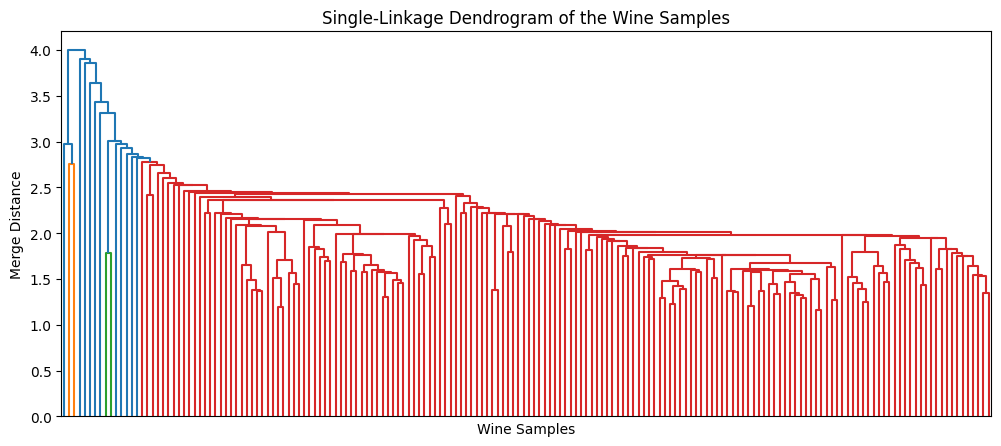

In [8]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method="single")

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True)
plt.title("Single-Linkage Dendrogram of the Wine Samples")
plt.xlabel("Wine Samples")
plt.ylabel("Merge Distance")
plt.show()

# Task 8

**Task 8:** In this step I test how useful each clustering result is by using it to predict the real wine type. I take the group labels from K-Means, DBSCAN, and HDBSCAN and turn each one into a set of 0/1 columns, one column per group. Noise wines get their own column. I split the 178 wines into 80% training and 20% testing, with the same share of each wine type in both, then train a Logistic Regression model that only sees these group columns and has to guess the real wine type. I also calculate the silhouette score for each method.

# Task 8 Code

K-Means: accuracy = 0.9722, silhouette = 0.2849
DBSCAN: accuracy = 0.3889, silhouette = 0.2392
HDBSCAN: accuracy = 0.7500, silhouette = 0.3524


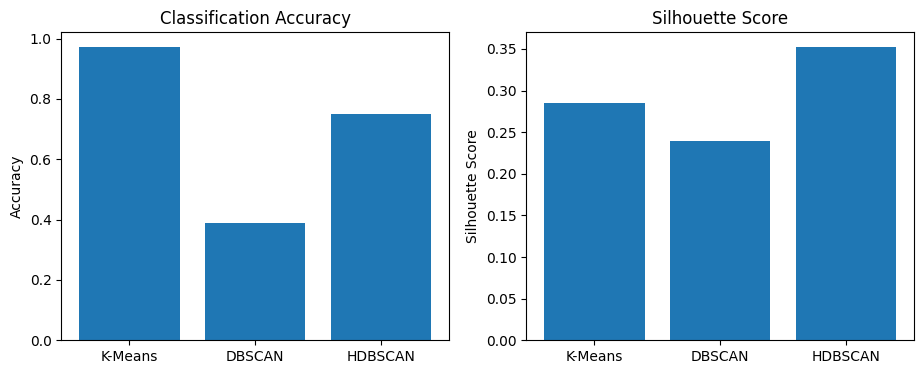

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

methods = {"K-Means": km13.labels_, "DBSCAN": db_labels, "HDBSCAN": hdb_labels}
accs = {}
sils = {}

for name, lab in methods.items():
    feats = pd.get_dummies(lab).values
    F_train, F_test, y_train, y_test = train_test_split(
        feats, y, test_size=0.2, random_state=42, stratify=y)
    clf = LogisticRegression(max_iter=1000)
    clf.fit(F_train, y_train)
    accs[name] = clf.score(F_test, y_test)
    keep = lab != -1
    sils[name] = silhouette_score(X_scaled[keep], lab[keep])
    print(f"{name}: accuracy = {accs[name]:.4f}, silhouette = {sils[name]:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].bar(accs.keys(), accs.values())
axes[0].set_title("Classification Accuracy")
axes[0].set_ylabel("Accuracy")
axes[1].bar(sils.keys(), sils.values())
axes[1].set_title("Silhouette Score")
axes[1].set_ylabel("Silhouette Score")
plt.show()